# **Predicting Complaint Escalation for Mobile Subscribers**

Zenith Mobile Networks wants to resolve complaints before they reach regulators. The service team needs a model predicting whether a subscriber's complaint will be escalated (Yes/No), using subscriber profile data, call quality logs and complaint ticket logs, to route risky cases to senior agents.


# Import files from the device

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving escalated_to_predict.csv to escalated_to_predict.csv
Saving escalated_labeled.csv to escalated_labeled.csv
Saving complaint_tickets.csv to complaint_tickets.csv
Saving subscriber_profile.csv to subscriber_profile.csv
Saving call_quality_logs.csv to call_quality_logs.csv


# Import libraries

In [ ]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Train-Test Split & Cross Validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

# Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    MinMaxScaler
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Feature Engineering
from sklearn.feature_selection import SelectKBest, mutual_info_classif

# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    RandomForestClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay
)

# Class Imbalance
from sklearn.utils.class_weight import compute_class_weight

# Model Interpretation
import shap

# Warnings
import warnings
warnings.filterwarnings('ignore')

# Load CSV files

In [ ]:
profile = pd.read_csv("subscriber_profile.csv")
calls = pd.read_csv("call_quality_logs.csv")
tickets = pd.read_csv("complaint_tickets.csv")
labels = pd.read_csv("escalated_labeled.csv")
test_ids = pd.read_csv("escalated_to_predict.csv")

# Profile Report

In [ ]:
!pip install fg-data-profiling --quiet

In [ ]:
import data_profiling
from data_profiling import ProfileReport

In [ ]:
profile1 = ProfileReport(profile, title="Profile Report - Subscriber Profile", explorative=True)
profile1.to_file("subscriber_profile_report.html")
files.download("subscriber_profile_report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 5/5 [00:00<00:00, 14.32it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

file:///C:/Users/DELL/Downloads/subscriber_profile_report%20(2).html

# Data cleaning/preprocssing

In [ ]:
print("Profile:", profile.shape)
print("Calls:", calls.shape)
print("Tickets:", tickets.shape)
print("Labels:", labels.shape)
print("Prediction IDs:", test_ids.shape)

Profile: (2360, 5)
Calls: (18920, 5)
Tickets: (5918, 5)
Labels: (2006, 2)
Prediction IDs: (354, 1)


# Profile

In [ ]:
profile.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2360 entries, 0 to 2359
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   subscriber_id  2360 non-null   object
 1   plan_type      2360 non-null   object
 2   tenure_months  2360 non-null   int64 
 3   region         2360 non-null   object
 4   segment        2274 non-null   object
dtypes: int64(1), object(4)
memory usage: 92.3+ KB


In [ ]:
profile.head()

,subscriber_id,plan_type,tenure_months,region,segment
0,SUB-0001,Prepaid,75,Urban,Consumer
1,SUB-0002,Prepaid,25,Urban,Enterprise
2,SUB-0003,Prepaid,70,Rural,Enterprise
3,SUB-0004,Postpaid,57,Rural,Consumer
4,SUB-0005,Postpaid,80,Semi-urban,Enterprise


In [ ]:
profile.describe()

,tenure_months
count,2360.00000
mean,48.78178
std,27.72626
min,1.00000
25%,25.00000
50%,49.00000
75%,73.00000
max,96.00000


In [ ]:
profile.columns

Index(['subscriber_id', 'plan_type', 'tenure_months', 'region', 'segment'], dtype='object')

In [ ]:
profile.duplicated().sum()

np.int64(0)

In [ ]:
profile.isnull().sum()

,0
subscriber_id,0
plan_type,0
tenure_months,0
region,0
segment,86


##plan_type

In [ ]:
profile['plan_type'].isnull().sum()

np.int64(0)

In [ ]:
profile['plan_type'].nunique()

3

In [ ]:
profile['plan_type'].value_counts(dropna=False)

,count
plan_type,
Prepaid,812
Postpaid,795
Family,753


Plan Type Distribution

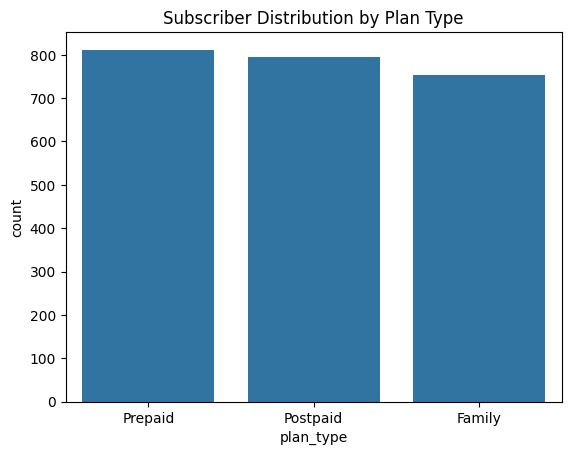

In [ ]:
sns.countplot(data=profile, x='plan_type')
plt.title('Subscriber Distribution by Plan Type')
plt.show()

## tenure_months

In [ ]:
(profile['tenure_months'] < 0).sum()

np.int64(0)

Tenure Distribution

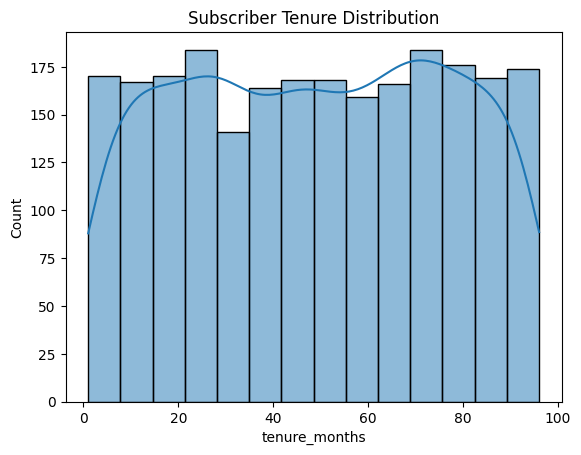

In [ ]:
sns.histplot(data=profile, x='tenure_months', kde=True)
plt.title('Subscriber Tenure Distribution')
plt.show()

## region

In [ ]:
profile['region'].value_counts(dropna=False)

,count
region,
Rural,802
Semi-urban,796
Urban,762


Region Distribution

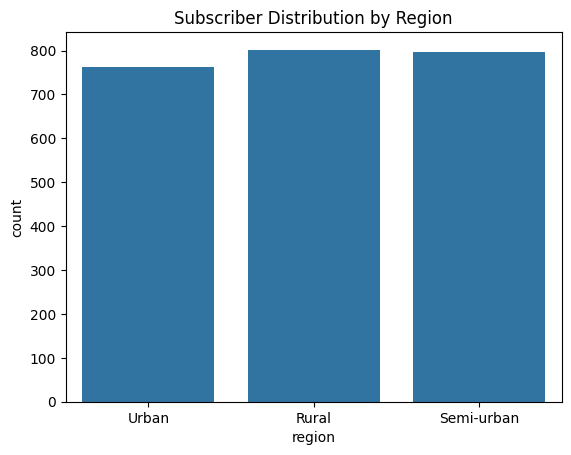

In [ ]:
sns.countplot(data=profile, x='region')
plt.title('Subscriber Distribution by Region')
plt.show()

## segment

missing values in segment

In [ ]:
profile['segment'].value_counts(dropna=False)

,count
segment,
Enterprise,793
SMB,746
Consumer,735
NaN,86


In [ ]:
(profile['segment'].isnull().sum()/len(profile['segment'])*100)

np.float64(3.6440677966101696)

86 nan , around 3.6%

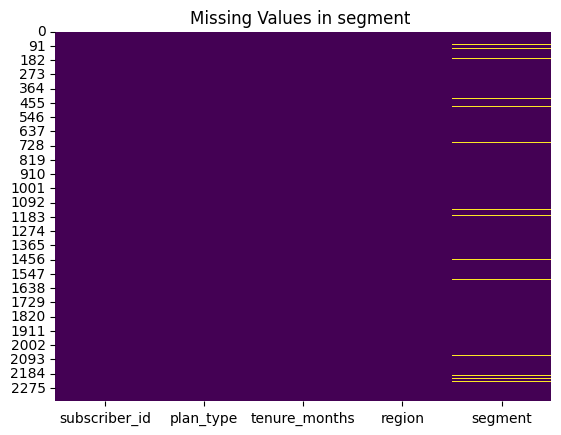

In [ ]:
sns.heatmap(profile.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values in segment ')
plt.show()

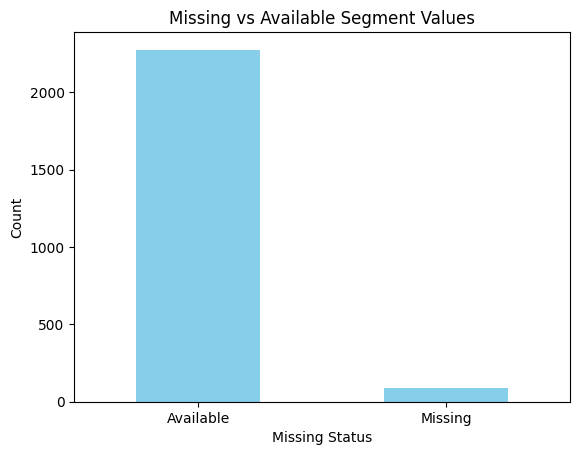

In [ ]:
profile['segment'].isnull().value_counts().plot(
    kind='bar',
    color='skyblue'
)

plt.title('Missing vs Available Segment Values')
plt.xlabel('Missing Status')
plt.ylabel('Count')
plt.xticks([0, 1], ['Available', 'Missing'], rotation=0)
plt.show()

Region vs Plan Type

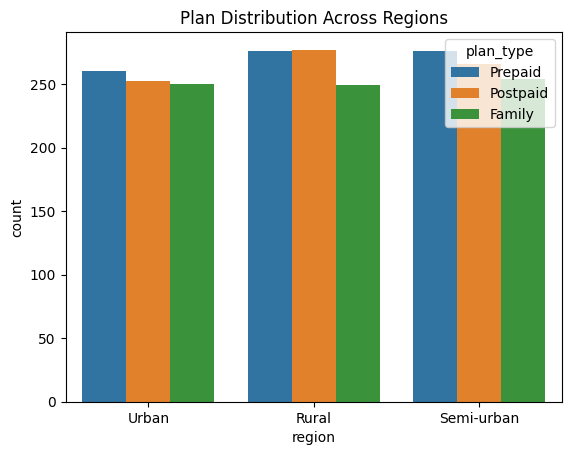

In [ ]:
sns.countplot(data=profile, x='region', hue='plan_type')
plt.title('Plan Distribution Across Regions')
plt.show()

# Calls

In [ ]:
calls.shape

(18920, 5)

In [ ]:
calls.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18920 entries, 0 to 18919
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   record_id      18920 non-null  object 
 1   subscriber_id  18920 non-null  object 
 2   log_date       18920 non-null  object 
 3   drop_rate_pct  18920 non-null  float64
 4   latency_ms     18920 non-null  float64
dtypes: float64(2), object(3)
memory usage: 739.2+ KB


In [ ]:
calls.head()

,record_id,subscriber_id,log_date,drop_rate_pct,latency_ms
0,CAL-010179,SUB-1264,2025-04-08,5.007695,96.763505
1,CAL-012783,SUB-1589,2024-03-19,2.351287,50.668099
2,CAL-015222,SUB-1891,2025-04-27,4.446157,116.269970
3,CAL-004430,SUB-0548,2024-02-13,4.856037,121.113496
4,CAL-002655,SUB-0321,2025-03-01,3.355997,73.453162


In [ ]:
calls.columns

Index(['record_id', 'subscriber_id', 'log_date', 'drop_rate_pct',
       'latency_ms'],
      dtype='object')

In [ ]:
calls.duplicated().sum()

np.int64(0)

In [ ]:
calls.describe()

,drop_rate_pct,latency_ms
count,18920.000000,18920.000000
mean,3.105919,80.002328
std,2.196201,40.673800
min,0.000000,-177.568169
25%,1.360035,55.963040
50%,2.981512,80.153841
75%,4.591428,103.537727
max,13.221263,384.750192


## log_date

In [ ]:
calls['log_date'] = pd.to_datetime(calls['log_date'], errors='coerce')

## drop_rate_pct

In [ ]:
(calls['drop_rate_pct'] < 0).sum()

np.int64(0)

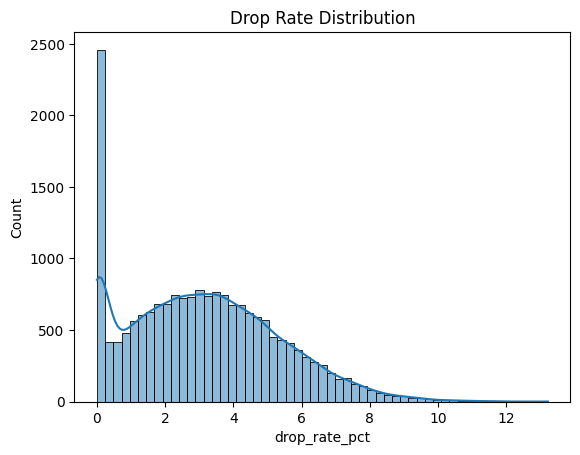

In [ ]:
sns.histplot(data=calls, x='drop_rate_pct', kde=True)
plt.title('Drop Rate Distribution')
plt.show()

## latency_ms

 outliers in latency_ms

In [ ]:
calls.shape


(18920, 5)

In [ ]:
(calls['latency_ms'] < 0).sum()

np.int64(170)

170 negative values

In [ ]:
calls[calls['latency_ms'] < 0].head()

,record_id,subscriber_id,log_date,drop_rate_pct,latency_ms
17,CAL-012962,SUB-1613,2023-12-19,1.256084,-90.156952
19,CAL-013868,SUB-1721,2024-05-06,0.371970,-155.692201
97,CAL-012596,SUB-1568,2024-11-12,5.384376,-121.479055
158,CAL-012469,SUB-1554,2023-07-24,3.276271,-120.222821
243,CAL-006448,SUB-0797,2023-09-17,0.694097,-97.928156


Ascending order (smallest to largest):

In [ ]:
calls[calls['latency_ms'] < 0].sort_values(
    by='latency_ms', ascending=True
).head(5)

,record_id,subscriber_id,log_date,drop_rate_pct,latency_ms
11386,CAL-013300,SUB-1653,2023-12-23,3.967106,-177.568169
13230,CAL-011556,SUB-1440,2024-08-01,1.800039,-173.096934
348,CAL-006332,SUB-0784,2025-02-09,0.000000,-168.516541
18485,CAL-012934,SUB-1608,2023-12-18,0.895412,-167.312361
18919,CAL-017403,SUB-2167,2025-03-17,0.000000,-161.909171


Descending order (largest to smallest):

In [ ]:
calls['latency_ms'].sort_values( ascending=False
).head(5)

,latency_ms
259,384.750192
7867,348.104502
13683,320.045050
17429,319.965018
15763,316.758107


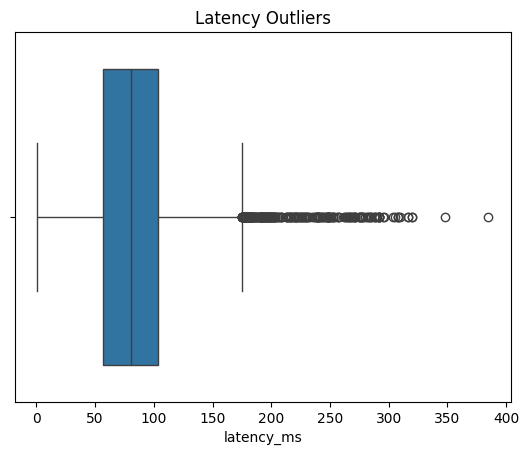

In [ ]:
sns.boxplot(data=calls, x='latency_ms')
plt.title('Latency Outliers')
plt.show()

Negative latency values were converted to positive after confirming they resulted from incorrect negative signs in the data.

In [ ]:
calls['latency_ms'] = calls['latency_ms'].abs()

verify

In [ ]:
(calls['latency_ms'] < 0).sum()

np.int64(0)

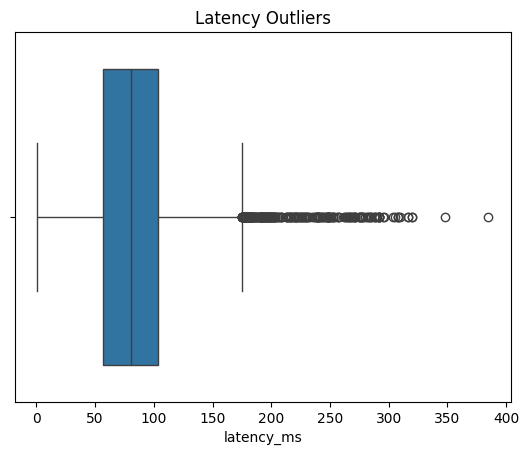

In [ ]:
sns.boxplot(data=calls, x='latency_ms')
plt.title('Latency Outliers')
plt.show()

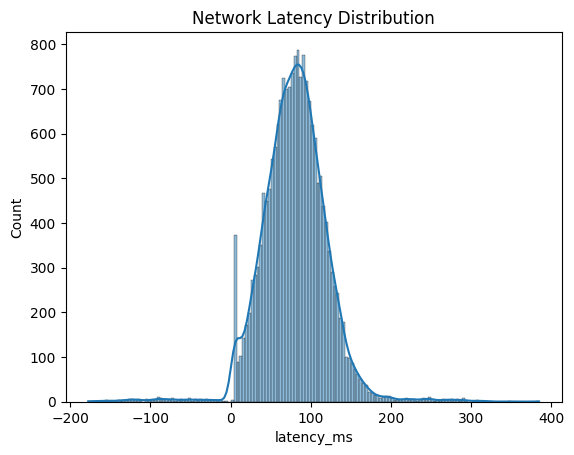

In [ ]:
sns.histplot(data=calls, x='latency_ms', kde=True)
plt.title('Network Latency Distribution')
plt.show()

# tickets

In [ ]:
tickets.shape

(5918, 5)

In [ ]:
tickets.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5918 entries, 0 to 5917
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   record_id      5918 non-null   object 
 1   subscriber_id  5918 non-null   object 
 2   ticket_date    5918 non-null   object 
 3   issue_type     5918 non-null   object 
 4   days_open      5772 non-null   float64
dtypes: float64(1), object(4)
memory usage: 231.3+ KB


In [ ]:
tickets.describe()

,days_open
count,5772.000000
mean,4.136001
std,2.630685
min,0.000000
25%,2.000000
50%,4.000000
75%,6.000000
max,14.000000


In [ ]:
tickets.columns

Index(['record_id', 'subscriber_id', 'ticket_date', 'issue_type', 'days_open'], dtype='object')

In [ ]:
tickets.duplicated().sum()

np.int64(0)

In [ ]:
tickets.head()

,record_id,subscriber_id,ticket_date,issue_type,days_open
0,COM-001316,SUB-0518,2023-08-03,SIM,8.0
1,COM-001478,SUB-0571,2025-04-09,Speed,3.0
2,COM-003236,SUB-1283,2023-08-04,Billing,5.0
3,COM-003471,SUB-1383,2024-11-04,SIM,6.0
4,COM-001690,SUB-0656,2024-11-08,SIM,9.0


## ticket_date

In [ ]:
tickets['ticket_date'] = pd.to_datetime(tickets['ticket_date'])

In [ ]:
tickets['ticket_date'].dtype

dtype('<M8[ns]')

## issue_type

In [ ]:
tickets['issue_type'].unique()

array(['SIM', 'Speed', 'Billing', 'Coverage'], dtype=object)

In [ ]:
tickets['issue_type'].value_counts(dropna=False)

,count
issue_type,
SIM,1554
Coverage,1495
Speed,1464
Billing,1405


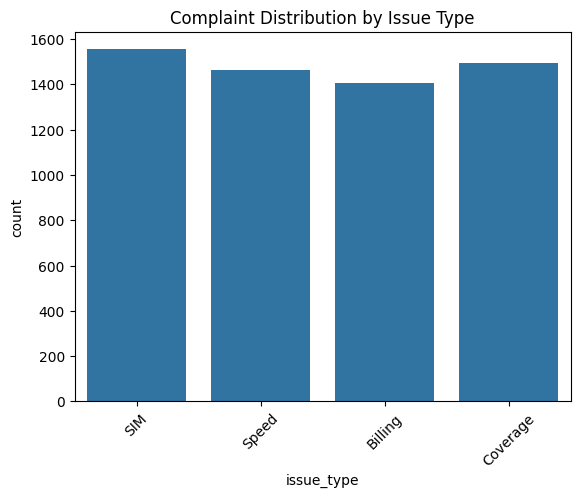

In [ ]:
sns.countplot(data=tickets, x='issue_type')
plt.title('Complaint Distribution by Issue Type')
plt.xticks(rotation=45)
plt.show()

## days_open

In [ ]:
tickets.isnull().sum()

,0
record_id,0
subscriber_id,0
ticket_date,0
issue_type,0
days_open,146


In [ ]:
(tickets['days_open'].isnull().sum()/len(tickets)*100)

np.float64(2.46704967894559)

days_open 146 null value around 2.4%

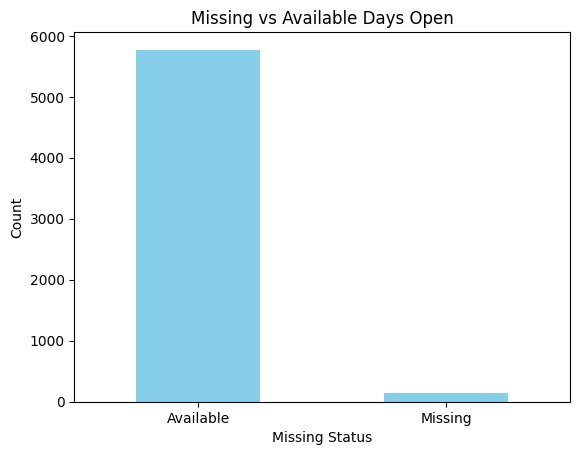

In [ ]:
tickets['days_open'].isnull().value_counts().plot(
    kind='bar', color='skyblue'
)

plt.title('Missing vs Available Days Open')
plt.xlabel('Missing Status')
plt.ylabel('Count')
plt.xticks([0, 1], ['Available', 'Missing'], rotation=0)
plt.show()

In [ ]:
(tickets['days_open'] < 0).sum()

np.int64(0)

# labels

In [ ]:
labels.shape

(2006, 2)

In [ ]:
labels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2006 entries, 0 to 2005
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   subscriber_id  2006 non-null   object
 1   escalated      2006 non-null   object
dtypes: object(2)
memory usage: 31.5+ KB


In [ ]:
labels.head()

,subscriber_id,escalated
0,SUB-0001,No
1,SUB-0002,No
2,SUB-0004,No
3,SUB-0005,No
4,SUB-0006,No


In [ ]:
labels.duplicated().sum()

np.int64(0)

In [ ]:
labels['escalated'].value_counts()

,count
escalated,
No,1380
Yes,626


Inspect subscriber_profile, call_quality_logs, complaint_tickets; find the shared key subscriber_id.

In [ ]:
# Check subscriber_id in all datasets
for name, df in {
    'Profile': profile,
    'Call Logs': calls,
    'Complaint Tickets': tickets
}.items():
    print(f"\n{name}:")
    print('subscriber_id exists:', 'subscriber_id' in df.columns)
    print('Unique subscribers:', df['subscriber_id'].nunique())
    print('Missing IDs:', df['subscriber_id'].isnull().sum())


Profile:
subscriber_id exists: True
Unique subscribers: 2360
Missing IDs: 0

Call Logs:
subscriber_id exists: True
Unique subscribers: 2360
Missing IDs: 0

Complaint Tickets:
subscriber_id exists: True
Unique subscribers: 1986
Missing IDs: 0


# Aggregate

Aggregate Call Quality Logs

In [ ]:
calls_agg = calls.groupby('subscriber_id').agg(
    total_calls=('record_id', 'count'),
    avg_drop_rate=('drop_rate_pct', 'mean'),
    max_drop_rate=('drop_rate_pct', 'max'),
    avg_latency=('latency_ms', 'mean'),
    max_latency=('latency_ms', 'max'),
    min_latency=('latency_ms', 'min')
).reset_index()

Aggregate Complaint Tickets

In [ ]:
tickets_agg = tickets.groupby('subscriber_id').agg(
    total_tickets=('record_id', 'count'),
    avg_days_open=('days_open', 'mean'),
    max_days_open=('days_open', 'max'),
    min_days_open=('days_open', 'min'),
    unique_issue_types=('issue_type', 'nunique')
).reset_index()

verify

In [ ]:
print(calls_agg.shape)
print(tickets_agg.shape)

display(calls_agg.head())
display(tickets_agg.head())

(2360, 7)
(1986, 6)


,subscriber_id,total_calls,avg_drop_rate,max_drop_rate,avg_latency,max_latency,min_latency
0,SUB-0001,9,0.665263,2.624902,44.955778,82.812969,5.000000
1,SUB-0002,11,4.326640,6.180856,96.847963,147.252078,55.600623
2,SUB-0003,10,2.360347,5.756660,81.535721,126.960983,50.113643
3,SUB-0004,5,2.339386,3.353883,67.114985,104.984036,30.980827
4,SUB-0005,12,3.928058,5.733826,114.696889,152.181193,71.522533


,subscriber_id,total_tickets,avg_days_open,max_days_open,min_days_open,unique_issue_types
0,SUB-0001,1,4.0,4.0,4.0,1
1,SUB-0003,1,7.0,7.0,7.0,1
2,SUB-0004,2,3.5,4.0,3.0,2
3,SUB-0005,2,2.5,5.0,0.0,2
4,SUB-0007,2,3.5,5.0,2.0,1


In [ ]:
print("Call aggregation duplicates:", calls_agg['subscriber_id'].duplicated().sum())
print("Ticket aggregation duplicates:", tickets_agg['subscriber_id'].duplicated().sum())

Call aggregation duplicates: 0
Ticket aggregation duplicates: 0


# Merge

Merge the aggregated features with subscriber_profile on subscriber_id.

In [ ]:
# Merge profile with call aggregates
df = profile.merge(calls_agg, on='subscriber_id', how='left')

# Merge complaint aggregates
df = df.merge(tickets_agg, on='subscriber_id', how='left')

# Check final dataset
print(df.shape)
display(df.head())

(2360, 16)


,subscriber_id,plan_type,tenure_months,region,segment,total_calls,avg_drop_rate,max_drop_rate,avg_latency,max_latency,min_latency,total_tickets,avg_days_open,max_days_open,min_days_open,unique_issue_types
0,SUB-0001,Prepaid,75,Urban,Consumer,9,0.665263,2.624902,44.955778,82.812969,5.000000,1.0,4.0,4.0,4.0,1.0
1,SUB-0002,Prepaid,25,Urban,Enterprise,11,4.326640,6.180856,96.847963,147.252078,55.600623,NaN,NaN,NaN,NaN,NaN
2,SUB-0003,Prepaid,70,Rural,Enterprise,10,2.360347,5.756660,81.535721,126.960983,50.113643,1.0,7.0,7.0,7.0,1.0
3,SUB-0004,Postpaid,57,Rural,Consumer,5,2.339386,3.353883,67.114985,104.984036,30.980827,2.0,3.5,4.0,3.0,2.0
4,SUB-0005,Postpaid,80,Semi-urban,Enterprise,12,3.928058,5.733826,114.696889,152.181193,71.522533,2.0,2.5,5.0,0.0,2.0


In [ ]:
print("Duplicate subscribers:", df['subscriber_id'].duplicated().sum())
print("Missing values:\n", df.isnull().sum())

Duplicate subscribers: 0
Missing values:
 subscriber_id           0
plan_type               0
tenure_months           0
region                  0
segment                86
total_calls             0
avg_drop_rate           0
max_drop_rate           0
avg_latency             0
max_latency             0
min_latency             0
total_tickets         374
avg_days_open         385
max_days_open         385
min_days_open         385
unique_issue_types    374
dtype: int64


In [ ]:
df[df['total_tickets'].isna()]['subscriber_id'].nunique()

374

374 subscribers have no complaint ticket records.



Fill total_tickets and unique_issue_types with 0

In [ ]:
df[['total_tickets', 'unique_issue_types']] = df[
    ['total_tickets', 'unique_issue_types']
].fillna(0)

## Merge Target Labels

In [ ]:
data = df.merge(labels, on='subscriber_id', how='inner')

verify

In [ ]:
print(data.shape)
print(data['escalated'].value_counts())
print(data['escalated'].isnull().sum())

(2006, 17)
escalated
No     1380
Yes     626
Name: count, dtype: int64
0


# Train-Test Split

In [ ]:
X = data.drop(columns=['subscriber_id', 'escalated'])
y = data['escalated']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

verify

In [ ]:
print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(1604, 15) (402, 15)
escalated
No     0.687656
Yes    0.312344
Name: proportion, dtype: float64
escalated
No     0.689055
Yes    0.310945
Name: proportion, dtype: float64


# Missing value imputation,Standardization,Encoding

Identify Numerical and Categorical Columns

In [ ]:
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()

cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['tenure_months', 'total_calls', 'avg_drop_rate', 'max_drop_rate', 'avg_latency', 'max_latency', 'min_latency', 'total_tickets', 'avg_days_open', 'max_days_open', 'min_days_open', 'unique_issue_types']
Categorical: ['plan_type', 'region', 'segment']


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

pipelines handle missing (NaN) values.
- Numerical columns: SimpleImputer(strategy='median') replaces NaN with the training median.
- Categorical columns: SimpleImputer(strategy='most_frequent') replaces NaN with the training mode.
- StandardScaler: Standardizes numerical features.
- OneHotEncoder: Converts categorical values into numerical columns.

## Fit and Transform the Data

In [ ]:
# Fit on training data and transform
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using training parameters
X_test_processed = preprocessor.transform(X_test)

fit_transform() → Learns imputation, scaling and encoding parameters from training data.



transform() → Applies the same parameters to test data.



Data leakage prevented.

fit_transform(X_train) → Imputation + Standardization + One-Hot Encoding.



transform(X_test) → Applies the same preprocessing learned from training data.

# Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

model.fit(X_train_processed, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [ ]:
y_pred = model.predict(X_test_processed)

In [ ]:
y_pred

array(['No', 'No', 'Yes', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'No',
       'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'Yes', 'No', 'No',
       'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No',
       'Yes', 'No', 'Yes', 'No', 'No', 'Yes', 'No', 'Yes', 'No', 'No',
       'No', 'No', 'No', 'No', 'Yes', 'Yes', 'No', 'No', 'No', 'No', 'No',
       'No', 'No', 'No', 'Yes', 'No', 'Yes', 'No', 'No', 'No', 'No', 'No',
       'No', 'No', 'Yes', 'Yes', 'No', 'Yes', 'No', 'No', 'No', 'No',
       'No', 'No', 'Yes', 'No', 'Yes', 'No', 'No', 'No', 'Yes', 'No',
       'No', 'Yes', 'No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No', 'No',
       'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No', 'No',
       'No', 'Yes', 'No', 'Yes', 'No', 'Yes', 'No', 'No', 'No', 'No',
       'No', 'Yes', 'No', 'Yes', 'No', 'No', 'Yes', 'No', 'No', 'No',
       'No', 'Yes', 'Yes', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No',
       'No', 'No', 'No', 'No', 'Yes', 'Yes', 'Yes', 'No'

# Model Evaluation

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label='Yes'))
print("Recall:", recall_score(y_test, y_pred, pos_label='Yes'))
print("F1 Score:", f1_score(y_test, y_pred, pos_label='Yes'))

print(classification_report(y_test, y_pred))

Accuracy: 0.736318407960199
Precision: 0.6
Recall: 0.456
F1 Score: 0.5181818181818182
              precision    recall  f1-score   support

          No       0.78      0.86      0.82       277
         Yes       0.60      0.46      0.52       125

    accuracy                           0.74       402
   macro avg       0.69      0.66      0.67       402
weighted avg       0.72      0.74      0.73       402



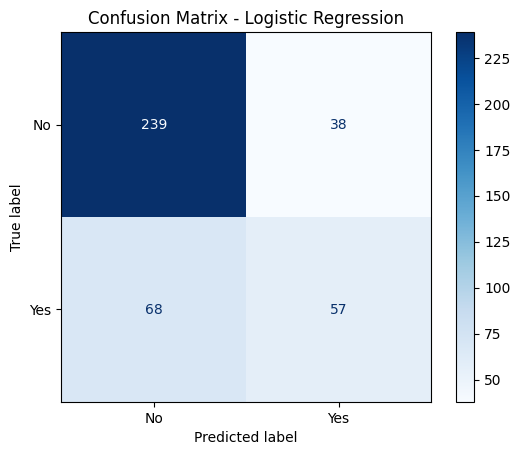

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=['No', 'Yes'])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
).plot(cmap='Blues')

plt.title('Confusion Matrix - Logistic Regression')
plt.show()

In [ ]:
model_balanced = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)

model_balanced.fit(X_train_processed, y_train)

y_pred_balanced = model_balanced.predict(X_test_processed)

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label='Yes'))
print("Recall:", recall_score(y_test, y_pred, pos_label='Yes'))
print("F1 Score:", f1_score(y_test, y_pred, pos_label='Yes'))

print(classification_report(y_test, y_pred))

Accuracy: 0.736318407960199
Precision: 0.6
Recall: 0.456
F1 Score: 0.5181818181818182
              precision    recall  f1-score   support

          No       0.78      0.86      0.82       277
         Yes       0.60      0.46      0.52       125

    accuracy                           0.74       402
   macro avg       0.69      0.66      0.67       402
weighted avg       0.72      0.74      0.73       402



# Cross-Validation

In [ ]:
from sklearn.metrics import make_scorer, f1_score

f1_scorer = make_scorer(f1_score, pos_label='Yes')

scores = cross_val_score(
    model_balanced,
    X_train_processed,
    y_train,
    cv=cv,
    scoring=f1_scorer
)

print("F1 Scores:", scores)
print("Mean F1:", scores.mean())
print("Std:", scores.std())

F1 Scores: [0.59591837 0.59459459 0.60444444 0.54693878 0.55084746]
Mean F1: 0.57854872790466
Std: 0.024479835835495116


# Hyperparameter Tuning

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

full_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__class_weight': ['balanced'],
    'classifier__solver': ['liblinear', 'lbfgs']
}

grid = GridSearchCV(
    full_pipeline,
    param_grid,
    cv=cv,
    scoring=f1_scorer,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)

Best Parameters: {'classifier__C': 0.01, 'classifier__class_weight': 'balanced', 'classifier__solver': 'liblinear'}
Best CV F1: 0.582396296641482


# Final test evaluation

In [ ]:
best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.86      0.69      0.76       277
         Yes       0.52      0.75      0.61       125

    accuracy                           0.71       402
   macro avg       0.69      0.72      0.69       402
weighted avg       0.75      0.71      0.72       402



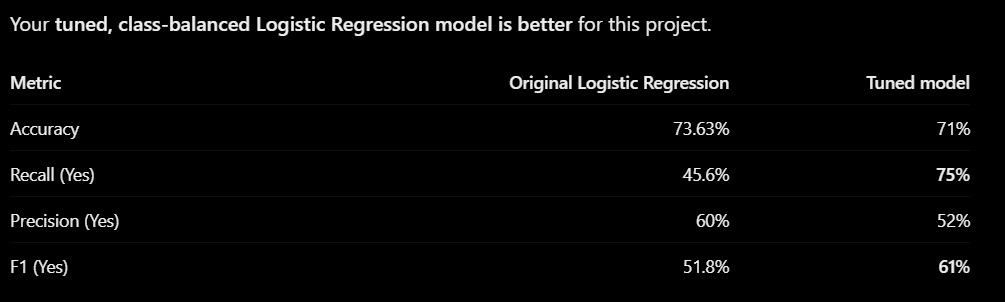

as it is have small imbalance in the data we dont only recall on accuracy

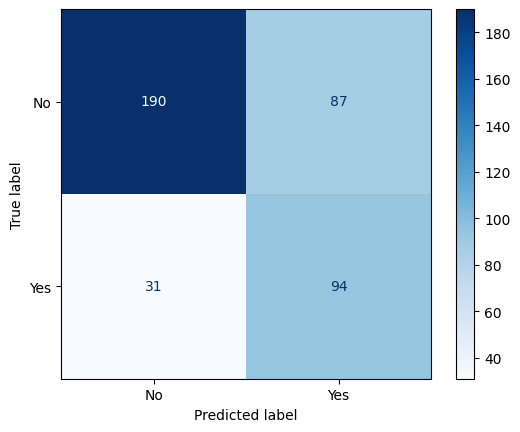

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=['No', 'Yes'])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
)

disp.plot(cmap='Blues')
plt.show()

In [ ]:
tn, fp, fn, tp = cm.ravel()

print("Correct predictions:", tn + tp)
print("Incorrect predictions:", fp + fn)

print("Correct No:", tn)
print("Correct Yes:", tp)

print("Wrong No (predicted Yes):", fp)
print("Missed Yes (predicted No):", fn)

Correct predictions: 295
Incorrect predictions: 107
Correct No: 246
Correct Yes: 49
Wrong No (predicted Yes): 31
Missed Yes (predicted No): 76


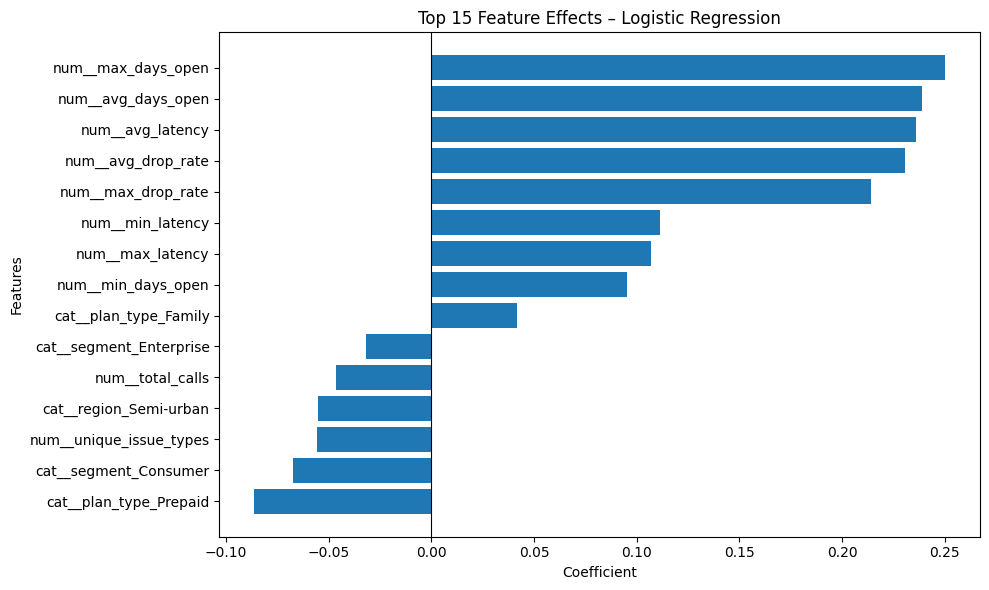

In [ ]:
import matplotlib.pyplot as plt

top_features = importance_df.head(15).sort_values('Coefficient')

plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'],
    top_features['Coefficient']
)

plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("Coefficient")
plt.ylabel("Features")
plt.title("Top 15 Feature Effects – Logistic Regression")
plt.tight_layout()
plt.show()

Positive bars → increase the tendency towards Yes.



Negative bars → increase the tendency towards No.

# Prepare data for prediction

In [ ]:
import pandas as pd

predict_ids = pd.read_csv('escalated_to_predict.csv')

# Get features for subscribers who need predictions
predict_data = predict_ids[['subscriber_id']].merge(
    df,
    on='subscriber_id',
    how='left'
)

# Remove identifier from model features
X_predict = predict_data.drop(columns=['subscriber_id'])

# Ensure the same feature columns and order as training
X_predict = X_predict[X_train.columns]

# Predict and save results

In [ ]:
# Get final tuned model
best_model = grid.best_estimator_

# Predict escalation
predictions = best_model.predict(X_predict)

# Get prediction probabilities
probabilities = best_model.predict_proba(X_predict)[:, 1]

# Create results dataframe
results = pd.DataFrame({
    'subscriber_id': predict_data['subscriber_id'],
    'escalated_prediction': predictions,
    'escalation_probability': probabilities
})

# Save predictions
results.to_csv('escalation_predictions.csv', index=False)

print(results.head())
print("Predictions saved successfully!")

  subscriber_id escalated_prediction  escalation_probability
0      SUB-0003                  Yes                0.610238
1      SUB-0008                   No                0.411510
2      SUB-0014                   No                0.469874
3      SUB-0025                  Yes                0.755964
4      SUB-0028                  Yes                0.921541
Predictions saved successfully!


# Save the trained model

In [ ]:
import joblib

joblib.dump(best_model, 'escalation_model.pkl')

print("Model saved successfully!")

Model saved successfully!


# Load the saved model later

In [ ]:
loaded_model = joblib.load('escalation_model.pkl')

new_predictions = loaded_model.predict(X_predict)